# NLP with Disaster Tweets - Fine-tuning DistilBERT

**Автор:** Назаров Владимир

**GitHub:** [github.com/AmbiValent17](https://github.com/AmbiValent17)

**Kaggle:** [NLP with Disaster Tweets](https://www.kaggle.com/competitions/nlp-getting-started/overview)

---

## О проекте

Fine-tuning предобученного трансформера **DistilBERT** для бинарной классификации
твитов: является ли сообщение описанием реального бедствия (`target=1`) или нет (`target=0`).

Цель - улучшить baseline (TF-IDF + LogisticRegression, F1 = 0.760) за счёт
контекстного представления текста. Ожидаемое преимущество: трансформер различает
переносный смысл (`this track is fire`) и реальные сообщения о бедствиях,
что было ограничением bag-of-words.

## Данные

- **Источник:** Kaggle Competition "NLP with Disaster Tweets" (Getting Started).
- **train.csv:** - 7 613 твитов (после очистки дубликатов - 7 485).
- **test.csv:** - 3 263 твита без `target`.
- **Метрика:** F1-score.
- **Очистка:** та же, что в `01_eda_and_baseline.ipynb` - удаление конфликтов
  меток и дубликатов по тексту.

## План ноутбука

1. Загрузка данных и токенизатора DistilBERT.
2. Токенизация текста (`max_length=64`).
3. Создание PyTorch Dataset и DataLoader.
4. Fine-tuning `DistilBertForSequenceClassification`.
5. Оценка F1 на 5-fold StratifiedKFold (для сравнения с baseline).
6. Сравнение с baseline и выводы.

## Стек

- Python 3.10+
- pandas, numpy
- PyTorch
- HuggingFace Transformers
- scikit-learn
- matplotlib, seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import re

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
import random

DATA_DIR = Path('data')
RANDOM_STATE = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
if device.type == 'cuda':
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## Обработка данных (как в baseline)

In [3]:
train = pd.read_csv(Path(DATA_DIR) / "train.csv")
test = pd.read_csv(Path(DATA_DIR) / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train['keyword'] = train['keyword'].fillna('none')
test['keyword'] = test['keyword'].fillna('none')
train = train.drop(columns=['location'])
test = test.drop(columns=['location'])

dup_mask = train['text'].duplicated(keep=False)
dups = train[dup_mask].sort_values('text').reset_index(drop=True)

print(f"Всего строк в train: {len(train)}")
print(f"Строк с дублирующимся текстом: {len(dups)}")
print(f"Уникальных текстов среди них: {dups['text'].nunique()}")
label_counts = dups.groupby('text')['target'].nunique()

conflict_texts = label_counts[label_counts > 1].index
same_label_texts = label_counts[label_counts == 1].index

print(f"Уникальных текстов с конфликтом меток: {len(conflict_texts)}")
print(f"Уникальных текстов с одинаковой меткой: {len(same_label_texts)}")

conflict_rows = dups[dups['text'].isin(conflict_texts)]
same_label_rows = dups[dups['text'].isin(same_label_texts)]

print(f"Строк в конфликтующих группах: {len(conflict_rows)}")
print(f"Строк в группах с одинаковой меткой: {len(same_label_rows)}")

train_clean = train[~train['text'].isin(conflict_texts)].copy()
train_clean = train_clean.drop_duplicates(subset='text', keep='first').reset_index(drop=True)

def minimal_clean_text(text):
    text = re.sub(r'&\w+;', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_clean['text'] = train_clean['text'].apply(minimal_clean_text)
test['text'] = test['text'].apply(minimal_clean_text)

Train shape: (7613, 5)
Test shape: (3263, 4)
Всего строк в train: 7613
Строк с дублирующимся текстом: 179
Уникальных текстов среди них: 69
Уникальных текстов с конфликтом меток: 18
Уникальных текстов с одинаковой меткой: 51
Строк в конфликтующих группах: 55
Строк в группах с одинаковой меткой: 124


In [4]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LEN = 64

tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

sample = train_clean['text'].iloc[2]
print("Текст:", sample)
encoded = tokenizer(sample, max_length=MAX_LEN, padding='max_length', truncation=True)
print("\nДекодированный текст:", tokenizer.decode(encoded['input_ids']))

Текст: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected

Декодированный текст: [CLS] all residents asked to ' shelter in place ' are being notified by officers. no other evacuation or shelter in place orders are expected [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [5]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=64):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer(
            text,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train_clean['text'].to_numpy(),
    train_clean['target'].to_numpy(),
    test_size=0.2,
    stratify=train_clean['target'].to_numpy(),
    random_state=RANDOM_STATE,
)

print(f"Train: {len(X_train)}, Val: {len(X_val)}")
print(f"Train classes: {np.bincount(y_train)}")
print(f"Val classes:   {np.bincount(y_val)}")

Train: 5988, Val: 1497
Train classes: [3438 2550]
Val classes:   [859 638]


In [7]:
BATCH_SIZE = 32

train_ds = TweetDataset(X_train, y_train, tokenizer, MAX_LEN)
val_ds = TweetDataset(X_val, y_val, tokenizer, MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

batch = next(iter(train_loader))
print("input_ids batch shape:", batch['input_ids'].shape)
print("labels batch shape:", batch['labels'].shape)

input_ids batch shape: torch.Size([32, 64])
labels batch shape: torch.Size([32])


### Обучение

In [25]:
model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
)
model.to(device)

for param in model.distilbert.embeddings.parameters():
    param.requires_grad = False

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Всего параметров: {total_params}")
print(f"Обучаемых параметров: {trainable_params}")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1061.27it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Всего параметров: 66955010
Обучаемых параметров: 43119362


In [26]:
from transformers import get_linear_schedule_with_warmup
import copy

EPOCHS = 8
LR = 2e-5
WARMUP_RATIO = 0.1
PATIENCE = 2

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

best_f1 = 0.0
patience_counter = 0
best_model_state = None

In [27]:
def train_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        total_loss += outputs.loss.item()

        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    f1 = f1_score(all_labels, all_preds)
    return total_loss / len(loader), f1, all_preds, all_labels

In [28]:
history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

for epoch in range(EPOCHS):
    train_loss = train_epoch(model, train_loader, optimizer, scheduler, device)
    val_loss, val_f1, _, _ = evaluate(model, val_loader, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | "
          f"val_F1={val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_counter = 0
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"---> Новый лучший F1: {best_f1:.4f}")
    else:
        patience_counter += 1
        print(f"---> Нет улучшения ({patience_counter}/{PATIENCE})")
        if patience_counter >= PATIENCE:
            print("Early stopping")
            break

if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"\nЗагружена лучшая модель с F1 = {best_f1:.4f}")

Epoch 1/8 | train_loss=0.5186 | val_loss=0.4296 | val_F1=0.7409
---> Новый лучший F1: 0.7409
Epoch 2/8 | train_loss=0.3714 | val_loss=0.4266 | val_F1=0.8012
---> Новый лучший F1: 0.8012
Epoch 3/8 | train_loss=0.2999 | val_loss=0.4487 | val_F1=0.7731
---> Нет улучшения (1/2)
Epoch 4/8 | train_loss=0.2387 | val_loss=0.4665 | val_F1=0.7863
---> Нет улучшения (2/2)
Early stopping

Загружена лучшая модель с F1 = 0.8012


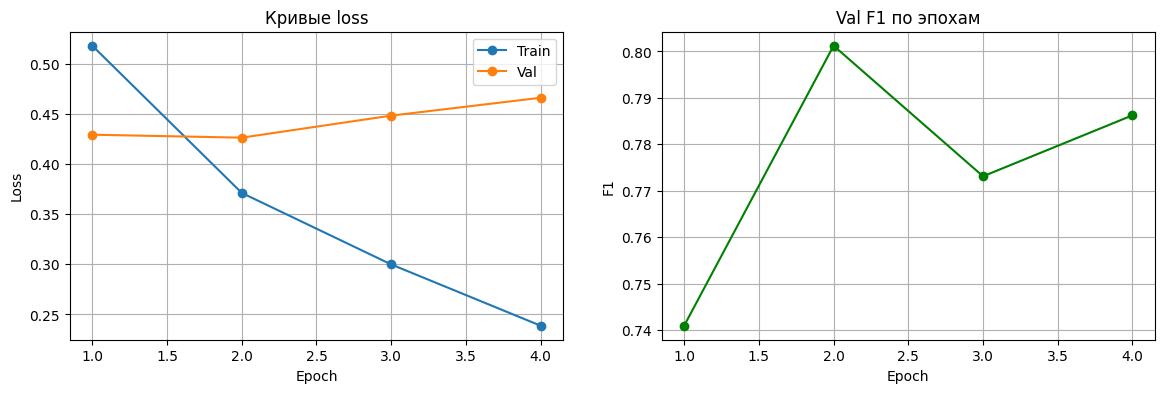

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

epochs_ran = len(history['train_loss'])

axes[0].plot(range(1, epochs_ran+1), history['train_loss'], marker='o', label='Train')
axes[0].plot(range(1, epochs_ran+1), history['val_loss'], marker='o', label='Val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Кривые loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(range(1, epochs_ran+1), history['val_f1'], marker='o', color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1')
axes[1].set_title('Val F1 по эпохам')
axes[1].grid(True)

plt.show()

In [35]:
model.eval()

test_ds = TweetDataset(
    test['text'].to_numpy(),
    np.zeros(len(test)),
    tokenizer,
    MAX_LEN
)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

all_preds = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())

submission = pd.DataFrame({
    'id': test['id'],
    'target': all_preds
})

submission.to_csv('submission.csv', index=False)
print(f"Сохранено {len(submission)} предсказаний в submission.csv")
print(submission['target'].value_counts())

Сохранено 3263 предсказаний в submission.csv
target
0    1916
1    1347
Name: count, dtype: int64


Итоговая метрика на test (kaggle) - 0.82868